# Controlled severity interaction experiment

Frequency is frozen from `projet-simplifie`; all severity variants share identical client folds and settings. Train severity on positive claims only; evaluate the final premium on every validation contract. This notebook displays the saved experiment. Run `experiments/severity_interactions.py` to repeat fitting.

Historical frequency calibration and model selection reused some OOF labels. The previous 80/20 holdout was also explored. These are comparative research results, not external validation or Kaggle scores.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
cwd=Path.cwd().resolve()
ROOT=next(p for p in [cwd,*cwd.parents] if (p/'integration_sources.json').exists())
report=json.loads((ROOT/'reports/severity_interactions/results.json').read_text())
assert report['protocol']['baseline_source_parity_exact']
assert report['protocol']['production_model_changed'] is False
print(report['decision'])
print('50,000 contracts; 2,917 positive claims; five client folds; fixed frequency.')

Retain production model
50,000 contracts; 2,917 positive claims; five client folds; fixed frequency.


## Final premium results

Lower RMSE is better. Each challenger adds the raw constituent variables as well as its interaction. The power/licence feature is power divided by (1 + principal-driver licence experience). The speed interaction uses the principal driver’s age. All bootstrap intervals are paired by client, use 2,000 resamples, and have 99% coverage before accounting for historical model exploration.

,premium_rmse,delta_rmse,folds_better_than_baseline,delta_client_bootstrap_99_interval,prior_holdout_rmse,severity_rmse_positive
baseline,541.610073,0.0,0,"[0.0, 0.0]",535.213925,1454.241574
main_effects,541.635344,0.025271,1,"[-0.06923505776536444, 0.12744381168209973]",535.105361,1451.866544
power_vehicle_age,541.64765,0.037577,1,"[-0.0691055863926448, 0.14864676410304434]",535.057587,1452.619653
power_license_experience,541.649609,0.039536,1,"[-0.058232464771354554, 0.14584253434164157]",535.083411,1452.559093
speed_driver_age,541.635302,0.025229,1,"[-0.06645831696567768, 0.1262423680564]",535.103405,1451.900366
all_interactions,541.660909,0.050836,2,"[-0.06297827132297527, 0.16300696878208212]",535.041443,1453.165164


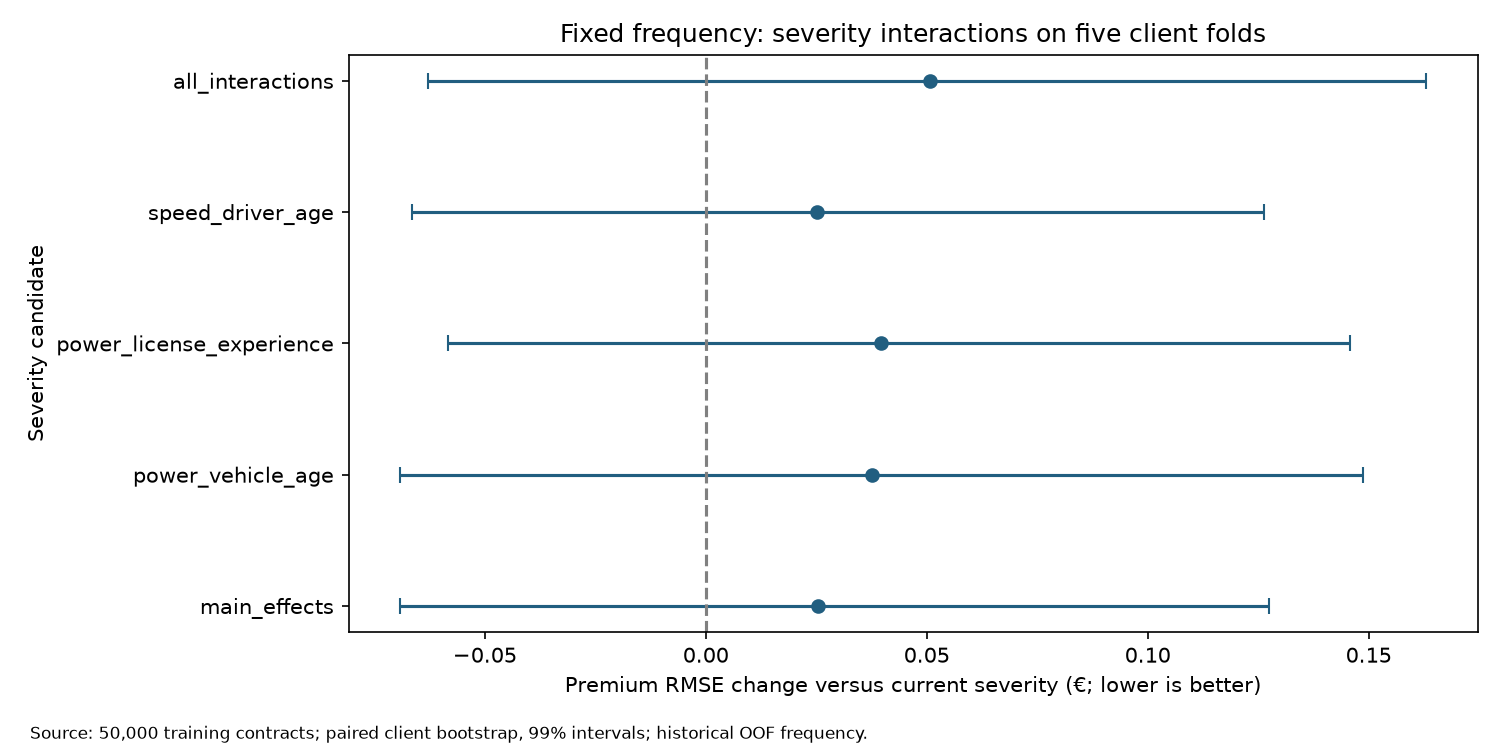

In [2]:
results=pd.DataFrame(report['results']).T
display(results[['premium_rmse','delta_rmse','folds_better_than_baseline','delta_client_bootstrap_99_interval','prior_holdout_rmse','severity_rmse_positive']])
display(Image(filename=str(ROOT/'reports/severity_interactions/comparison.png')))

## Fold stability and decision

Promotion required a negative upper 99% difference bound, improvement in at least four folds, and improvement on the previous holdout. No candidate passes. Retain the current full-data production model and its submission. A small improvement on the old holdout alone does not justify a change.

In [3]:
folds=pd.DataFrame({v:r['fold_rmse'] for v,r in report['results'].items()},index=[f'Fold {k}' for k in range(1,6)])
display(folds)
assert report['eligible_challengers']==[]
print('Current production model retained.')

,baseline,main_effects,power_vehicle_age,power_license_experience,speed_driver_age,all_interactions
Fold 1,553.115101,552.964254,553.054303,552.977773,552.959780,553.068710
Fold 2,558.858211,559.026307,559.015261,559.065533,559.022213,559.060069
Fold 3,530.243051,530.306387,530.273180,530.279192,530.294595,530.231718
Fold 4,501.672897,501.709803,501.708677,501.685125,501.708514,501.674881
Fold 5,561.794600,561.804945,561.818962,561.869080,561.825505,561.893423


Current production model retained.
